In [1]:
'Up and running'

'Up and running'

In [2]:
# Third-party modules
import numpy as np
import pandas as pd
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt

# Custom modules
from misc import path

In [ ]:
# Store data
rmsds = []
rmsfs = []
rgs = []

# Iterate over simulations
repetitions = [4, 6]
systems = ['WT', 'ST58AN']
for reps, system in zip(repetitions, systems):
    for repetition in tqdm(range(reps), desc=f'Processing {system}'):

        # Set directory
        directory = (
            path.SIMULATION / 'FUL-AG' / system / 
            str(repetition)
        )

        # RMSD data
        rmsd = pd.read_csv(directory / 'rmsd.csv')
        rmsd['System'] = system
        rmsd['Repetition'] = repetition
        rmsds.append(rmsd)

        # RMSF data
        rmsf = pd.read_csv(directory / 'rmsf.csv')
        rmsf['System'] = system
        rmsf['Repetition'] = repetition
        rmsfs.append(rmsf)

        # RG data
        rg = pd.read_csv(directory / 'rg.csv')
        rg['System'] = system
        rg['Repetition'] = repetition
        rgs.append(rg)

# Concatenate all data
rmsd = pd.concat(rmsds, ignore_index=True)
rmsf = pd.concat(rmsfs, ignore_index=True)
rg = pd.concat(rgs, ignore_index=True)

Processing ST58AN: 100%|██████████| 6/6 [00:01<00:00,  5.00it/s]


# RMSD

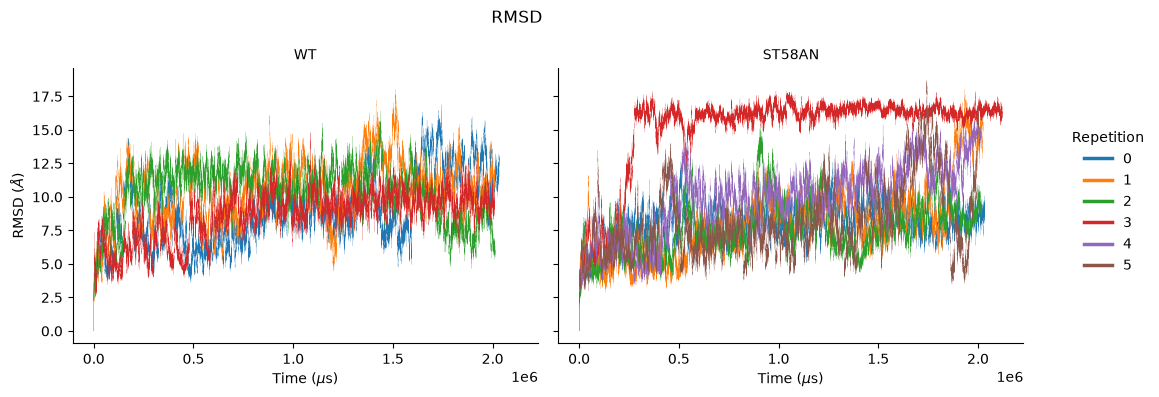

In [17]:
g = sns.relplot(
    data=rmsd,
    x="Time",
    y="RMSD",
    col="System",
    hue="Repetition",
    kind="line",
    estimator=None,
    units="Repetition",
    palette="tab10",
    linewidth=0.1,
    height=4,
    aspect=1.2,
    facet_kws={"sharey": True}
)

# Move legend outside the plots
sns.move_legend(
    g,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Repetition",
    frameon=False
)

legend = g._legend
for line in legend.get_lines():
        line.set_linewidth(2.5)
        
g.set_axis_labels(r"Time ($\mu$s)", r"RMSD ($\AA$)")
g.set_titles("{col_name}")
g.figure.suptitle('RMSD')

plt.tight_layout()
sns.despine()
plt.show()

# RMSF

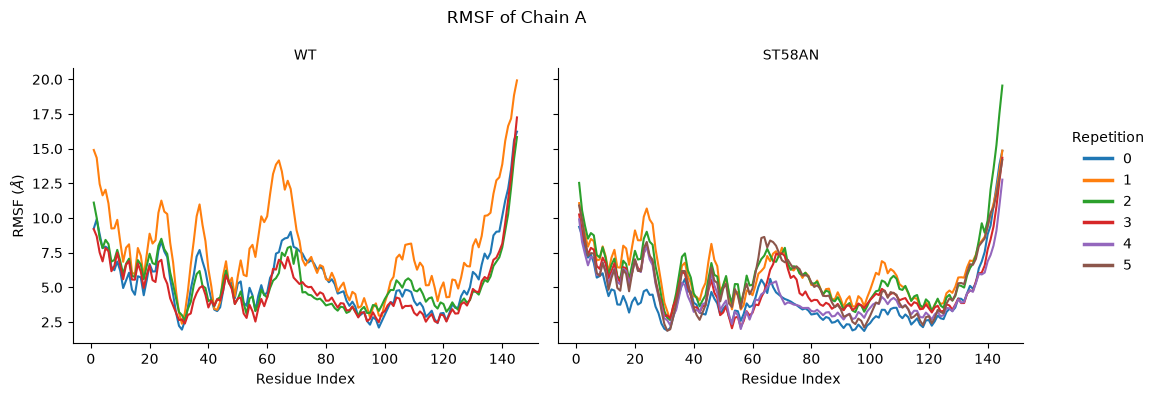

In [18]:
g = sns.relplot(
    data=rmsf[rmsf['Chain'] == 'A'],
    x="Residue",
    y="RMSF",
    col="System",
    hue="Repetition",
    kind="line",
    estimator=None,
    units="Repetition",
    palette="tab10",
    linewidth=1.5,
    height=4,
    aspect=1.2,
    facet_kws={"sharey": True}
)

# Move legend outside the plots
sns.move_legend(
    g,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Repetition",
    frameon=False
)

legend = g._legend
for line in legend.get_lines():
        line.set_linewidth(2.5)
        
g.set_axis_labels(r"Residue Index", r"RMSF ($\AA$)")
g.set_titles("{col_name}")
g.figure.suptitle('RMSF of Chain A')

plt.tight_layout()
sns.despine()
plt.show()

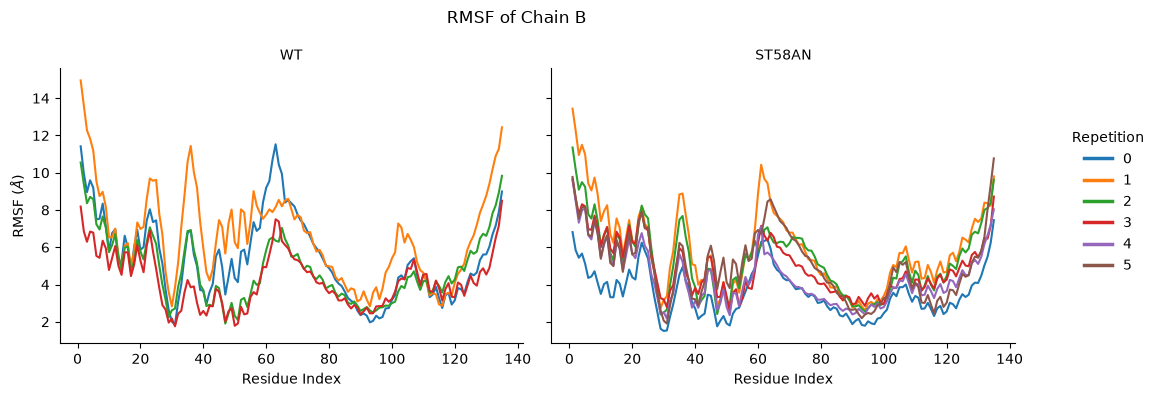

In [19]:
g = sns.relplot(
    data=rmsf[rmsf['Chain'] == 'B'],
    x="Residue",
    y="RMSF",
    col="System",
    hue="Repetition",
    kind="line",
    estimator=None,
    units="Repetition",
    palette="tab10",
    linewidth=1.5,
    height=4,
    aspect=1.2,
    facet_kws={"sharey": True}
)

# Move legend outside the plots
sns.move_legend(
    g,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Repetition",
    frameon=False
)

legend = g._legend
for line in legend.get_lines():
        line.set_linewidth(2.5)
        
g.set_axis_labels(r"Residue Index", r"RMSF ($\AA$)")
g.set_titles("{col_name}")
g.figure.suptitle('RMSF of Chain B')

plt.tight_layout()
sns.despine()
plt.show()

# Rg

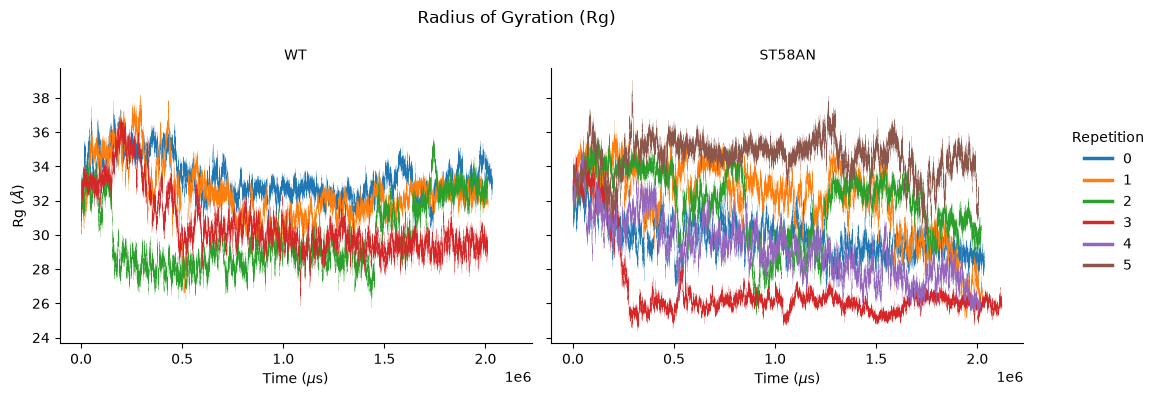

In [20]:
g = sns.relplot(
    data=rg,
    x="Time",
    y="Rg",
    col="System",
    hue="Repetition",
    kind="line",
    estimator=None,
    units="Repetition",
    palette="tab10",
    linewidth=0.1,
    height=4,
    aspect=1.2,
    facet_kws={"sharey": True}
)

# Move legend outside the plots
sns.move_legend(
    g,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    title="Repetition",
    frameon=False
)

legend = g._legend
for line in legend.get_lines():
        line.set_linewidth(2.5)

g.set_axis_labels(r"Time ($\mu$s)", r"Rg ($\AA$)")
g.set_titles("{col_name}")
g.figure.suptitle('Radius of Gyration (Rg)')

plt.tight_layout()
sns.despine()
plt.show()

# PCA

In [ ]:
# Load data
df = pd.read_csv(path.DATA / 'pca.csv')
df['Simulation'] = df['System'] + ' #' + df['Repetition'].astype(str)
print(df)

# Explained variance
variance = np.load(path.PCA / 'explained_variance.npy')

            PC1         PC2  System  Repetition   Frame Simulation
0     164.37138 -151.377910      WT           0       0      WT #0
1     343.36658   -0.400428      WT           0    1000      WT #0
2     305.08426  -93.028885      WT           0    2000      WT #0
3     464.50980 -309.586940      WT           0    3000      WT #0
4     370.19708    6.661816      WT           0    4000      WT #0
...         ...         ...     ...         ...     ...        ...
1014  439.30374  -36.950670  ST58AN           5   96000  ST58AN #5
1015  477.87875   65.986990  ST58AN           5   97000  ST58AN #5
1016  521.94934  -14.408388  ST58AN           5   98000  ST58AN #5
1017  662.18660   35.967300  ST58AN           5   99000  ST58AN #5
1018  549.85004  353.345300  ST58AN           5  100000  ST58AN #5

[1019 rows x 6 columns]


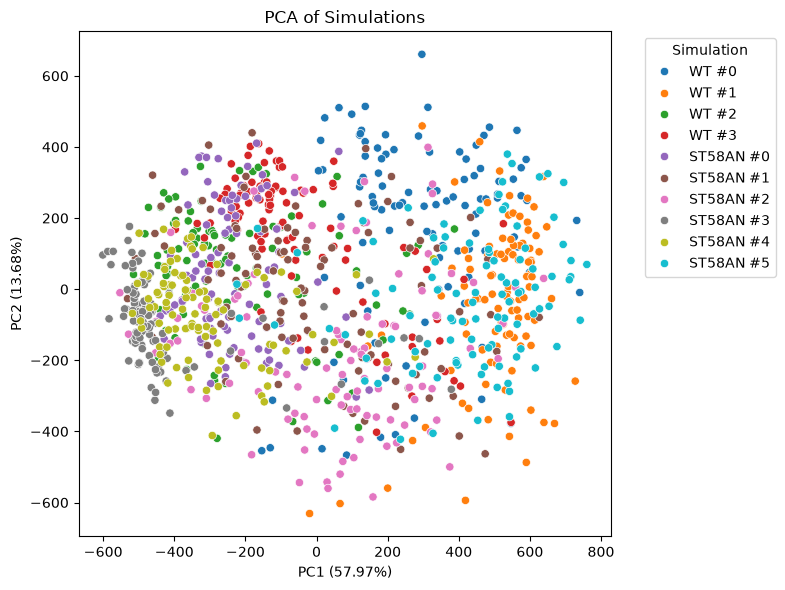

In [6]:
# # Joint scatterplot
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="PC1",
    y="PC2",
    hue="Simulation",
    palette="tab10",
)
plt.xlabel(f"PC1 ({variance[0]:.2f}%)")
plt.ylabel(f"PC2 ({variance[1]:.2f}%)")
plt.title("PCA of Simulations")
plt.legend(title="Simulation", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

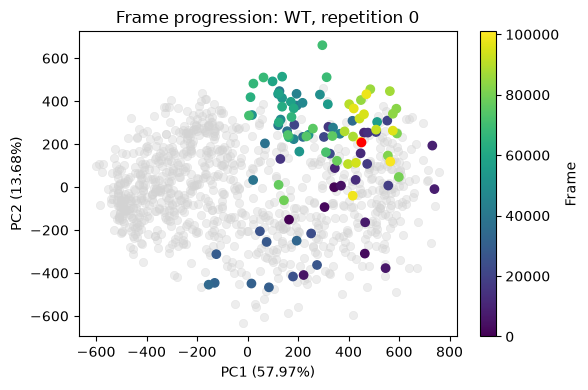

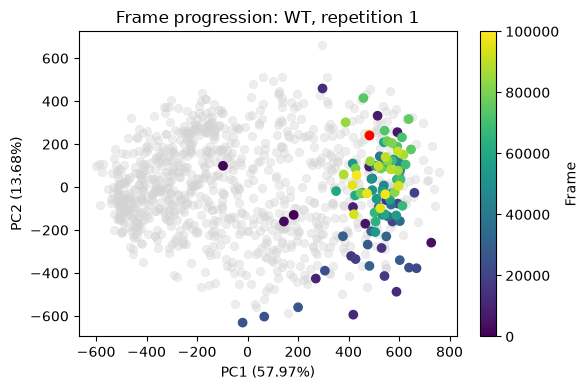

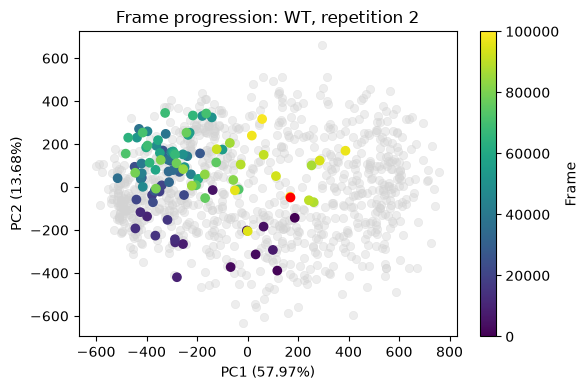

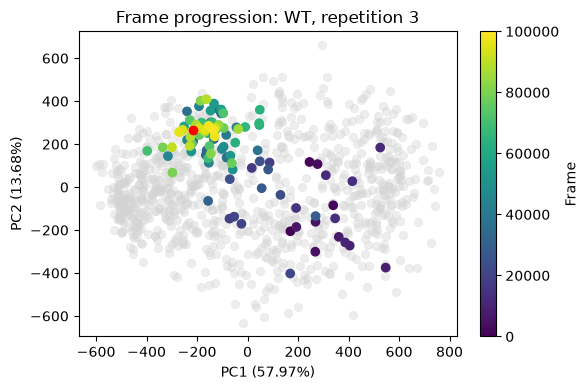

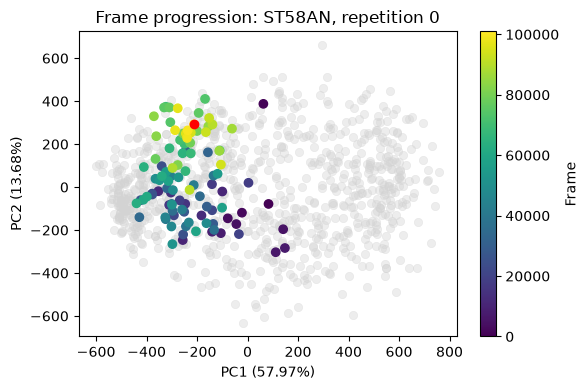

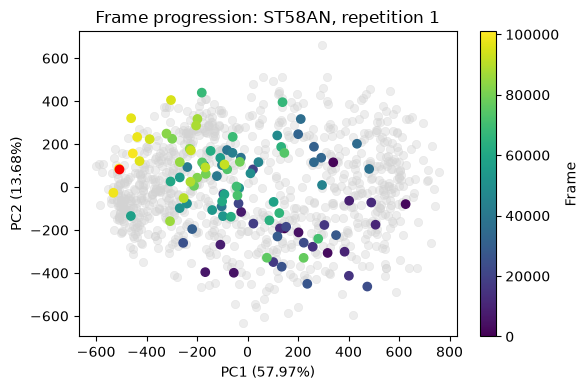

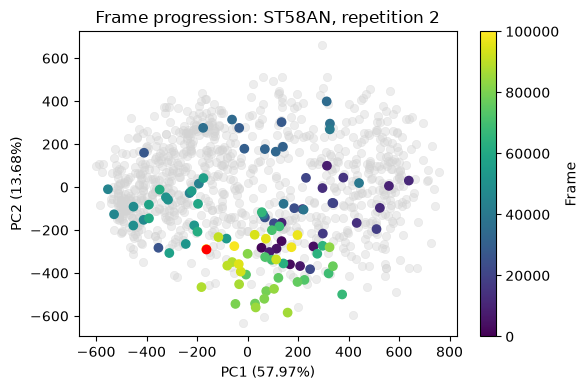

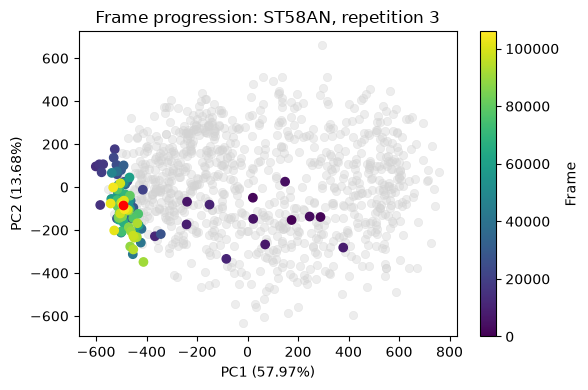

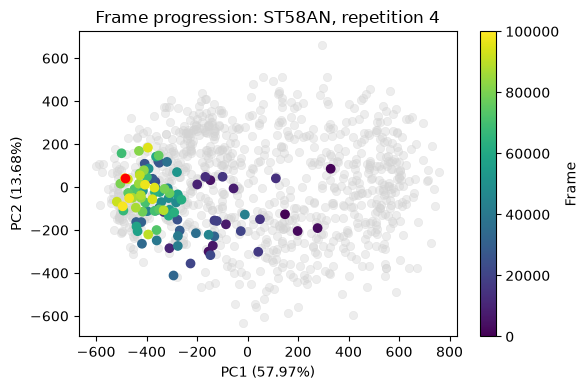

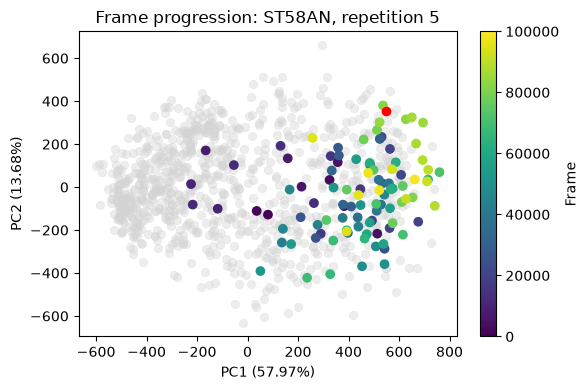

In [7]:
# Individual scatterplots
for system in df['System'].unique():
    for repetition in df[df['System'] == system]['Repetition'].unique():
        
        # Select the combination to highlight
        highlight = (df["System"] == system) & (df["Repetition"] == repetition)

        # Plot grey 
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.scatterplot(
            data=df[~highlight],
            x="PC1",
            y="PC2",
            color="lightgrey",
            alpha=0.4,
            edgecolor=None,
            legend=False,
            ax=ax
        )

        # Plot highlighted
        points = ax.scatter(
            df.loc[highlight, "PC1"],
            df.loc[highlight, "PC2"],
            c=df.loc[highlight, "Frame"],
            cmap="viridis",
        )

        # Plot last
        last = ax.scatter(
            df.loc[highlight, "PC1"].iloc[-1],
            df.loc[highlight, "PC2"].iloc[-1],
            color="red",
            label="Last Frame"
        )

        # Colorbar
        cbar = fig.colorbar(points, ax=ax)
        cbar.set_label("Frame")

        # Titles
        ax.set_xlabel(f"PC1 ({variance[0]:.2f}%)")
        ax.set_ylabel(f"PC2 ({variance[1]:.2f}%)")
        ax.set_title(f"Frame progression: {system}, repetition {repetition}")
        plt.tight_layout()
        plt.show()